# 03 · The water bonus model

**Question.** On the same crop, in the same district and the same season, how much more does an irrigated
plot yield than a rain-fed one?

**Model** (one regression per crop, small farmers, 2020–2025 Seasons A and B):

$$\log(\text{kg/ha}) = \beta\,\text{irrigated} + \text{district×year×season} + \text{crops on plot}
  + \text{fertilizer} + \text{improved seed} + \log(\text{plot ha}) + \text{crop variety} + \varepsilon$$

- District × year × season fixed effects absorb local rain, prices and pests that season.
- Errors are clustered by survey segment-year (plots in one segment share a surveyor and a hillside).
- The extreme 1% of yields at each end are dropped per crop (unit slips in kg or m²).
- The **water bonus** is $e^\beta - 1$.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from kuhira import style
from kuhira.paths import INTERIM
from kuhira.water_bonus import CROPS, estimate_all, estimate_within, prepare

style.use()
plots = pd.read_parquet(INTERIM / "plots.parquet")
bonus = estimate_all(plots)
bonus.to_csv(INTERIM / "water_bonus.csv", index=False)
bonus

,crop,plots,irrigated_plots,bonus_pct,ci_low_pct,ci_high_pct,p_value
0,Maize,61878,982,14.6,7.9,21.8,0.0000
1,Beans,93134,741,-10.3,-15.9,-4.3,0.0009
2,Irish potato,17619,214,9.7,-1.7,22.6,0.0994
3,Sweet potato,24233,387,15.2,7.9,22.8,0.0000
4,Vegetables,6605,2056,20.3,12.9,28.2,0.0000
5,Sorghum,18396,88,-4.0,-17.9,12.3,0.6112
6,Cassava,21013,134,-3.5,-15.2,9.7,0.5842
7,Paddy rice,566,424,9.0,-0.6,19.5,0.0655
8,Soybean,13395,125,-1.0,-14.5,14.7,0.8939
9,Wheat,1468,1,NaN,NaN,NaN,NaN


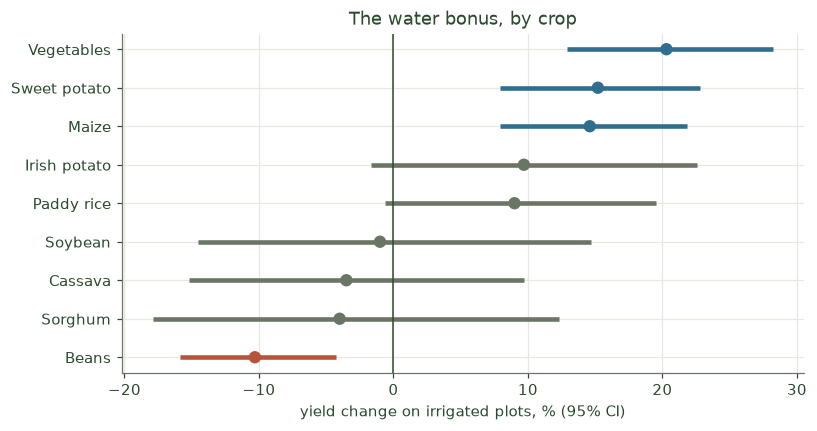

In [2]:
shown = bonus.dropna(subset=["bonus_pct"]).sort_values("bonus_pct")
colors = [style.CLAY if h < 0 else style.WATER if lo > 0 else style.MUTED
          for lo, h in zip(shown.ci_low_pct, shown.ci_high_pct)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.hlines(shown.crop, shown.ci_low_pct, shown.ci_high_pct, color=colors, lw=3)
ax.scatter(shown.bonus_pct, shown.crop, color=colors, s=50, zorder=3)
ax.axvline(0, color=style.FOREST, lw=1)
ax.set(xlabel="yield change on irrigated plots, % (95% CI)", title="The water bonus, by crop");

**Reading it.** Blue = clearly positive, clay = clearly negative, grey = cannot tell apart from zero.

- **Vegetables, maize and sweet potato** gain clearly, about +15–20%.
- **Beans lose about 10%** on irrigated plots. Likely reasons: irrigated plots sit in valley bottoms and
  marshland, where waterlogging and disease hurt beans, and farmers may irrigate beans late as a rescue.
  Either way, a hectare of irrigation is worth less where beans dominate, and the planner reflects that.
- Irish potato and rice lean positive but their intervals cross zero. Rice is mostly irrigated already, so
  there are few rain-fed rice plots to compare against.
- Sorghum, cassava and soybean show no effect. Wheat has one irrigated plot and is not estimated.

The planner counts a crop's bonus **only when p < 0.05**; others count as zero.

## Robustness 1: fit without dummy variables
The dummy-variable fit warns about a near-singular design (thousands of district-season cells). Demeaning
within district × year × season × crop cells fits the same model with no dummies at all.

In [3]:
df = prepare(plots)
within = pd.DataFrame([estimate_within(df, c) for c in ["Maize", "Beans", "Vegetables", "Sweet potato"]])
within.merge(bonus[["crop", "bonus_pct"]], on="crop", suffixes=("_within", "_main"))

,crop,bonus_pct_within,ci_low_pct,ci_high_pct,bonus_pct_main
0,Maize,14.6,7.9,21.8,14.6
1,Beans,-9.5,-15.0,-3.6,-10.3
2,Vegetables,20.3,13.1,27.9,20.3
3,Sweet potato,15.2,8.0,22.8,15.2


The estimates agree closely, so the warning does not move the answer.

## Robustness 2: year by year
If the bonus were a fluke of one bad season it would swing wildly between years. Pooling two years at a time:

In [4]:
rows = []
for years in [(2020, 2021), (2022, 2023), (2024, 2025)]:
    part = estimate_all(plots[plots.year.isin(years)])
    rows.append(part.assign(years=f"{years[0]}–{str(years[1])[2:]}")[["years", "crop", "bonus_pct", "p_value"]])
by_period = pd.concat(rows).pivot(index="crop", columns="years", values="bonus_pct").loc[
    ["Maize", "Beans", "Sweet potato", "Vegetables"]]
by_period

years,2020–21,2022–23,2024–25
crop,,,
Maize,11.3,22.1,11.0
Beans,-13.5,1.1,-18.0
Sweet potato,8.9,17.9,17.6
Vegetables,28.3,20.0,11.9


Maize, sweet potato and vegetables stay positive in every period, so the planner can lean on them. **Beans are
negative in 2020–21 and 2024–25 but flat in 2022–23**: the pooled −10% is real on average but not the same every
year, and the app says so. Sizes move around, as you would expect from a third of the data.